# Análise de Dados — FitStore

**Disciplina 2 — Análise de Dados**

Projeto Integrador — Ciência da Computação

**Objetivo:** Analisar as vendas, os produtos e o estoque da FitStore, utilizando Python para identificar os produtos mais vendidos, acompanhar o faturamento e auxiliar nas decisões de reposição de estoque.

**Base de dados**: Os dados utilizados nesta análise são fictícios e foram criados para simular as vendas e o controle de estoque da FitStore. O objetivo é aplicar os conhecimentos de análise de dados em situações que poderiam acontecer em uma empresa real.

In [ ]:

import pandas as pd


In [ ]:
from google.colab import files

arquivos = files.upload()

Saving BASE DE DADOS — FITSTORE - BASE DE DADOS — FITSTORE (1).csv to BASE DE DADOS — FITSTORE - BASE DE DADOS — FITSTORE (1) (1).csv


In [ ]:
caminho = "/content/" + list(arquivos.keys())[0]
print(caminho)

/content/BASE DE DADOS — FITSTORE - BASE DE DADOS — FITSTORE (1) (1).csv


In [ ]:

dados = pd.read_csv(caminho)

dados.head()


,ID da Venda,Data da Venda,Produto,Categoria,Quantidade Vendida,Preço Unitário,Valor Total,Estoque Atual,Status do Pedido,Alerta de Estoque
0,1,01/10/2026,Creatina,Suplementos,2,"R$ 89,90","R$ 179,80",18,Entregue,Estoque Normal
1,2,02/10/2026,Whey Protein,Suplementos,3,"R$ 129,90","R$ 389,70",25,Entregue,Estoque Normal
2,3,03/10/2026,Pré-treino,Suplementos,2,"R$ 79,90","R$ 159,80",12,Entregue,Estoque Normal
3,4,04/10/2026,Garrafa de Academia,Acessórios,4,"R$ 29,90","R$ 119,60",30,Entregue,Estoque Normal
4,5,05/10/2026,Camiseta Esportiva,Vestuário,2,"R$ 49,90","R$ 99,80",20,Entregue,Estoque Normal


In [ ]:

dados.shape


(11, 10)

In [ ]:

dados.isnull().sum()


,0
ID da Venda,0
Data da Venda,0
Produto,0
Categoria,0
Quantidade Vendida,0
Preço Unitário,0
Valor Total,0
Estoque Atual,0
Status do Pedido,0
Alerta de Estoque,0


In [ ]:

dados.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11 entries, 0 to 10
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   ID da Venda         11 non-null     int64 
 1   Data da Venda       11 non-null     object
 2   Produto             11 non-null     object
 3   Categoria           11 non-null     object
 4   Quantidade Vendida  11 non-null     int64 
 5   Preço Unitário      11 non-null     object
 6   Valor Total         11 non-null     object
 7   Estoque Atual       11 non-null     int64 
 8   Status do Pedido    11 non-null     object
 9   Alerta de Estoque   11 non-null     object
dtypes: int64(3), object(7)
memory usage: 1012.0+ bytes


In [ ]:

dados["Preço Unitário"] = (
    dados["Preço Unitário"]
    .str.replace("R$", "", regex=False)
    .str.replace(".", "", regex=False)
    .str.replace(",", ".", regex=False)
    .str.strip()
    .astype(float)
)

dados["Preço Unitário"].head()


,Preço Unitário
0,89.9
1,129.9
2,79.9
3,29.9
4,49.9


In [ ]:

dados["Valor Total"] = (
    dados["Valor Total"]
    .str.replace("R$", "", regex=False)
    .str.replace(".", "", regex=False)
    .str.replace(",", ".", regex=False)
    .str.strip()
    .astype(float)
)

dados["Valor Total"].head()


,Valor Total
0,179.8
1,389.7
2,159.8
3,119.6
4,99.8


## **Limpeza e Validação dos Dados — FitStore**

In [ ]:
dados["Total Calculado"] = (
    dados["Quantidade Vendida"] * dados["Preço Unitário"]
)
dados["Diferença"] = (
    dados["Valor Total"] - dados["Total Calculado"]
).round(2)

print(dados[["Produto", "Valor Total", "Total Calculado", "Diferença"]])

                Produto  Valor Total  Total Calculado  Diferença
0              Creatina       179.80           179.80        0.0
1          Whey Protein       389.70           389.70       -0.0
2            Pré-treino       159.80           159.80        0.0
3   Garrafa de Academia       119.60           119.60        0.0
4    Camiseta Esportiva        99.80            99.80        0.0
5                 Strap       119.70           119.70        0.0
6            Macaquinho       559.60           559.60        0.0
7              Creatina       449.50           449.50        0.0
8               Cafeína       149.70           149.70        0.0
9       Bolsa Esportiva       399.98           399.98        0.0
10             Creatina       359.60           359.60        0.0


É importante porque conseguimos verificar se os valores das vendas estão corretos e identificar possíveis erros nos cálculos. Assim, podemos analisar o faturamento da FitStore com mais segurança.

## **Indicadores de Desempenho (KPIs) — FitStore**

Faturamento Total: É importante porque ajuda a FitStore a ter uma noção de quanto dinheiro conseguiu com as vendas. Com essa informação, podemos acompanhar os resultados da empresa e verificar se as vendas estão aumentando ou diminuindo.

In [ ]:

faturamento_total = dados["Valor Total"].sum()

print(f"Faturamento total: R$ {faturamento_total:.2f}")


Faturamento total: R$ 2986.78


**Quantidade Total de Produtos Vendidos**: É importante porque ajuda a FitStore a organizar o estoque e identificar quais produtos vendem mais e quais vendem menos. Com essas informações, conseguimos planejar melhor a reposição dos produtos e evitar que os mais vendidos fiquem sem estoque.

In [ ]:

unidades_vendidas = dados["Quantidade Vendida"].sum()

print(f"Total de unidades vendidas: {unidades_vendidas}")


Total de unidades vendidas: 34


**Ticket Médio**: É importante porque ajuda a FitStore a identificar quanto os clientes gastam, em média, em cada compra. Para aumentar esse valor, a empresa poderia oferecer promoções, descontos e combos de produtos, além de investir na qualidade e nas avaliações dos clientes.

In [ ]:

ticket_medio = dados["Valor Total"].mean()

print(f"Ticket médio: R$ {ticket_medio:.2f}")


Ticket médio: R$ 271.53


## **Relação dos KPIs com os Objetivos da FitStore**

Esses três indicadores ajudam a FitStore porque conseguimos analisar quantos produtos foram vendidos, o faturamento total e o ticket médio. Com essas informações, podemos organizar melhor as vendas e o estoque, estudar estratégias para vender mais e aproveitar melhor as oportunidades de compra dos clientes.

## **Métodos Estatísticos — FitStore**

In [ ]:

mediana_vendas = dados["Valor Total"].median()

print(f"Mediana das vendas: R$ {mediana_vendas:.2f}")


Mediana das vendas: R$ 179.80


A média das vendas ficou maior que a mediana porque tivemos vendas com valores mais altos e outras com valores mais baixos. Um exemplo foi o Macaquinho, que teve 4 unidades vendidas e gerou R$ 559,60. Essas vendas de valores altos aumentaram a média, enquanto a mediana representa o valor que ficou no meio das vendas analisadas.

In [ ]:

desvio_padrao = dados["Valor Total"].std()

print(f"Desvio padrão das vendas: R$ {desvio_padrao:.2f}")


Desvio padrão das vendas: R$ 162.56


O desvio padrão é importante porque ajuda a FitStore a entender a diferença entre os valores das vendas. Algumas compras possuem valores maiores e outras menores, dependendo dos produtos e das quantidades compradas. Com essa informação, conseguimos analisar melhor o comportamento das vendas e pensar em estratégias para melhorar os resultados.

In [ ]:

import matplotlib.pyplot as plt


In [ ]:

produtos_mais_vendidos = dados.groupby("Produto")["Quantidade Vendida"].sum()

print(produtos_mais_vendidos)


Produto
Bolsa Esportiva         2
Cafeína                 3
Camiseta Esportiva      2
Creatina               11
Garrafa de Academia     4
Macaquinho              4
Pré-treino              2
Strap                   3
Whey Protein            3
Name: Quantidade Vendida, dtype: int64


## **Visualização dos Dados — FitStore**

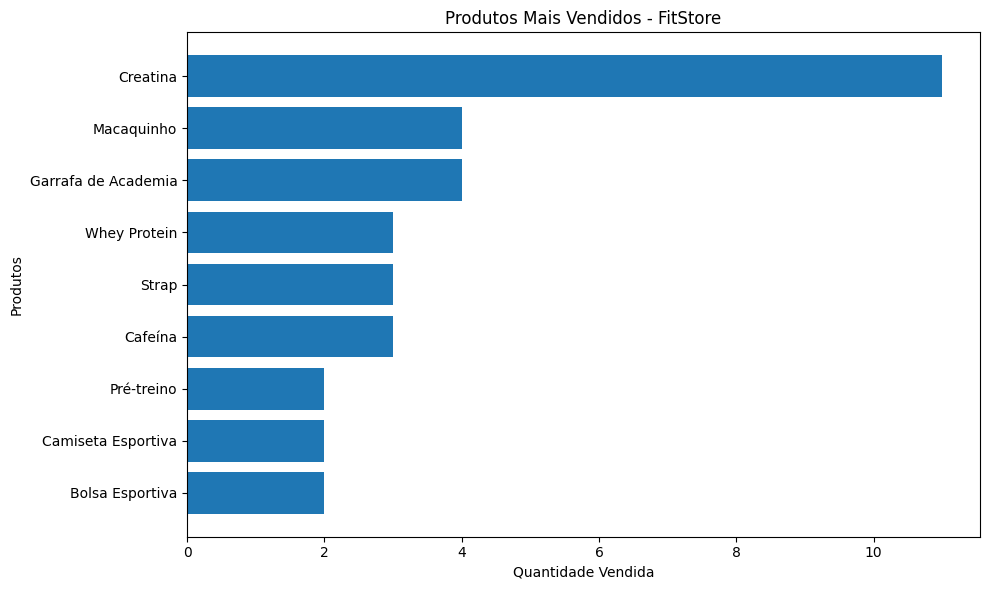

In [ ]:

produtos_ordenados = produtos_mais_vendidos.sort_values()

plt.figure(figsize=(10, 6))
plt.barh(produtos_ordenados.index, produtos_ordenados.values)

plt.title("Produtos Mais Vendidos - FitStore")
plt.xlabel("Quantidade Vendida")
plt.ylabel("Produtos")

plt.tight_layout()
plt.show()


In [ ]:

faturamento_produtos = dados.groupby("Produto")["Valor Total"].sum()

faturamento_produtos = faturamento_produtos.sort_values(ascending=False)

print(faturamento_produtos)


Produto
Creatina               988.90
Macaquinho             559.60
Bolsa Esportiva        399.98
Whey Protein           389.70
Pré-treino             159.80
Cafeína                149.70
Strap                  119.70
Garrafa de Academia    119.60
Camiseta Esportiva      99.80
Name: Valor Total, dtype: float64


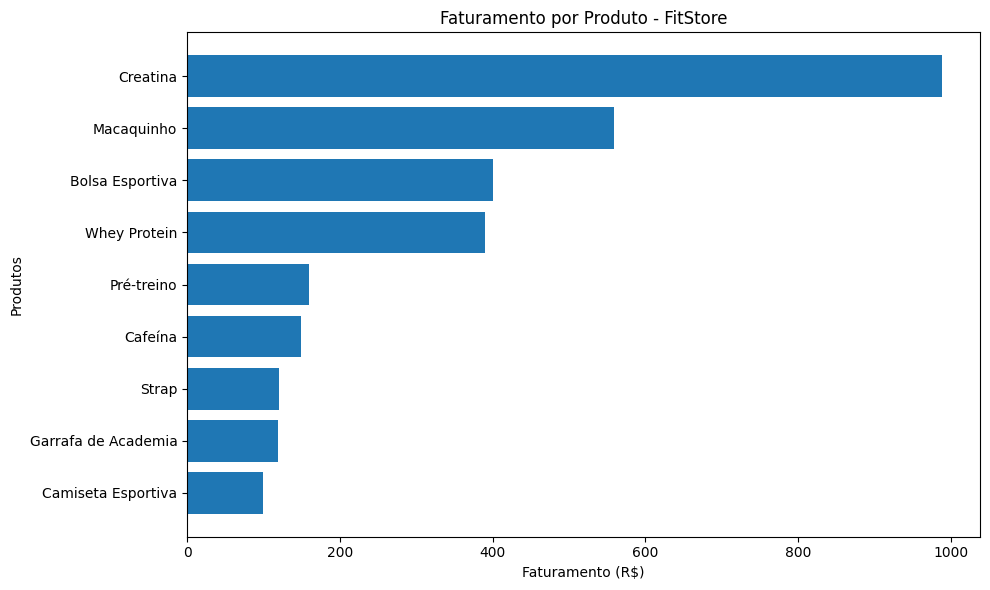

In [ ]:

plt.figure(figsize=(10, 6))

plt.barh(faturamento_produtos.index, faturamento_produtos.values)

plt.title("Faturamento por Produto - FitStore")
plt.xlabel("Faturamento (R$)")
plt.ylabel("Produtos")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [ ]:

estoque_baixo = dados[dados["Alerta de Estoque"] == "Estoque Baixo"]

print(estoque_baixo[["Produto", "Estoque Atual"]])


            Produto  Estoque Atual
9   Bolsa Esportiva              8
10         Creatina              9


Para esta análise, definimos como exemplo um estoque desejado de 20 unidades por produto. Com isso, conseguimos calcular quantas unidades precisam ser compradas para repor os produtos que estão com estoque baixo.

In [ ]:

estoque_desejado = 20

estoque_baixo = estoque_baixo.copy()

estoque_baixo["Quantidade para Repor"] = (
    estoque_desejado - estoque_baixo["Estoque Atual"]
)

print(estoque_baixo[["Produto", "Estoque Atual", "Quantidade para Repor"]])


            Produto  Estoque Atual  Quantidade para Repor
9   Bolsa Esportiva              8                     12
10         Creatina              9                     11


Porque é um produto que tem uma demanda alta, ele está sendo bastante vendido, mesmo a Bolsa Esportiva tenha menos produto, ela saiu em pouca quantidade, diferente da Creatina que teve 11 unidades vendidas, e atualmente conta com 9 unidades no estoque.

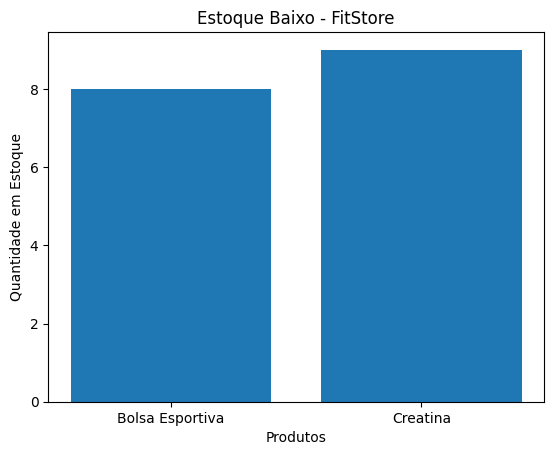

In [ ]:
plt.bar(estoque_baixo["Produto"], estoque_baixo["Estoque Atual"])

plt.title("Estoque Baixo - FitStore")
plt.xlabel("Produtos")
plt.ylabel("Quantidade em Estoque")

plt.show()

In [ ]:
dados["Data da Venda"] = pd.to_datetime(
    dados["Data da Venda"], dayfirst=True
)

vendas_por_dia = dados.groupby("Data da Venda")["Valor Total"].sum()

print(vendas_por_dia)

Data da Venda
2026-10-01    179.80
2026-10-02    389.70
2026-10-03    159.80
2026-10-04    119.60
2026-10-05     99.80
2026-10-06    119.70
2026-10-07    559.60
2026-10-08    449.50
2026-10-09    149.70
2026-10-10    399.98
2026-10-11    359.60
Name: Valor Total, dtype: float64


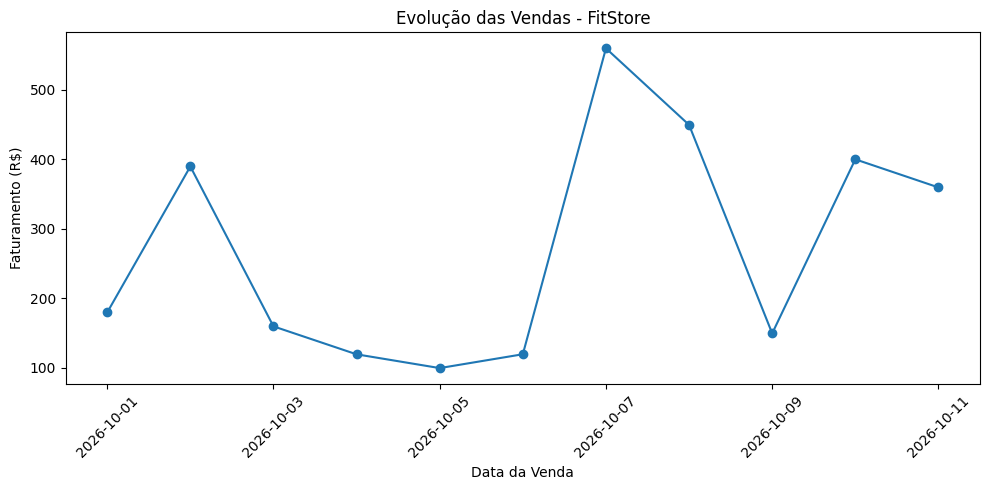

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(vendas_por_dia.index, vendas_por_dia.values, marker="o")

plt.title("Evolução das Vendas - FitStore")
plt.xlabel("Data da Venda")
plt.ylabel("Faturamento (R$)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Algumas estratégias boas seriam colocar promoções nos produtos que menos venderam porquê chamaria a atenção des clientes e colocaria em destaque produtos que venderam muito.

In [ ]:
print(dados.isnull().sum())

ID da Venda           0
Data da Venda         0
Produto               0
Categoria             0
Quantidade Vendida    0
Preço Unitário        0
Valor Total           0
Estoque Atual         0
Status do Pedido      0
Alerta de Estoque     0
Total Calculado       0
Diferença             0
dtype: int64


É importante porque conseguimos analisar todas as vendas e verificar se está faltando alguma informação. Assim, evitamos problemas na análise dos dados e conseguimos ter resultados mais confiáveis.

In [ ]:
print("Vendas duplicadas:", dados["ID da Venda"].duplicated().sum())

Vendas duplicadas: 0


Poderia causar um erro no faturamento, pois o sistema mostraria que vendeu mais produtos do que realmente vendeu, já que a mesma venda foi registrada duas vezes.

In [ ]:
vendas_invalidas = dados[
    (dados["Quantidade Vendida"] <= 0) |
    (dados["Preço Unitário"] <= 0)
]

print(vendas_invalidas)

Empty DataFrame
Columns: [ID da Venda, Data da Venda, Produto, Categoria, Quantidade Vendida, Preço Unitário, Valor Total, Estoque Atual, Status do Pedido, Alerta de Estoque, Total Calculado, Diferença]
Index: []


A análise de vendas poderia apresentar resultados errados, porque não faz sentido registrar uma venda com quantidade negativa, como -3 unidades. Isso poderia prejudicar o cálculo do faturamento e a quantidade de produtos vendidos.

## **Resumo da Limpeza e Validação dos Dados — FitStore**

Durante a análise da base de dados da FitStore, verificamos se existiam informações faltando, vendas duplicadas, valores incorretos e quantidades negativas. Não encontramos nenhum desses problemas nas 11 vendas analisadas. Com essas verificações, conseguimos ter mais segurança e confiança nos dados para realizar as análises.

## **Análise Crítica dos Resultados**

Durante a análise dos dados da FitStore, percebi que a Creatina é um dos produtos mais vendidos, com 11 unidades vendidas e apenas 9 unidades restantes no estoque. Isso pode ser um problema, porque, se o produto acabar, os clientes não conseguirão comprar e a empresa poderá perder vendas. Para evitar isso, a FitStore deveria comprar mais Creatinas com o fornecedor, atualizar o estoque no site e acompanhar a quantidade disponível.

Durante a análise das vendas da FitStore, percebemos que a empresa ainda está no começo e conseguiu faturar R$ 2.986,78, com 34 unidades vendidas. Alguns produtos venderam mais que outros, e isso pode acontecer por causa dos preços, da qualidade e das necessidades dos clientes. Uma boa estratégia seria fazer promoções nos produtos que vendem pouco para chamar a atenção dos clientes e também investir nos produtos mais vendidos, acompanhando a procura para não faltar mercadorias no estoque.